In [2]:
# 1. IMPORT SEMUA LIBRARY YANG DIBUTUHKAN
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

print("Semua library berhasil dimuat!")

Semua library berhasil dimuat!


In [3]:
# 2. MEMUAT DATASET
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dimensi Dataset:", X.shape)
print("Kelas Target:", data.target_names)

Dimensi Dataset: (569, 30)
Kelas Target: ['malignant' 'benign']


In [4]:
# 3. PEMBAGIAN DATASET (70% TRAINING, 30% TESTING)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print(f"Jumlah data training: {X_train.shape[0]}")
print(f"Jumlah data testing: {X_test.shape[0]}")

Jumlah data training: 398
Jumlah data testing: 171


In [5]:
# 4. PELATIHAN MODEL
# Model A: Logistic Regression (dengan Scaling)
model_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)
model_lr.fit(X_train, y_train)
y_pred_lr = model_lr.predict(X_test)

# Model B: Random Forest Classifier
model_rf = RandomForestClassifier(random_state=42, n_estimators=100)
model_rf.fit(X_train, y_train)
y_pred_rf = model_rf.predict(X_test)

print("Kedua model telah berhasil dilatih!")

Kedua model telah berhasil dilatih!


Akurasi Logistic Regression: 98.83%
Akurasi Random Forest: 93.57%


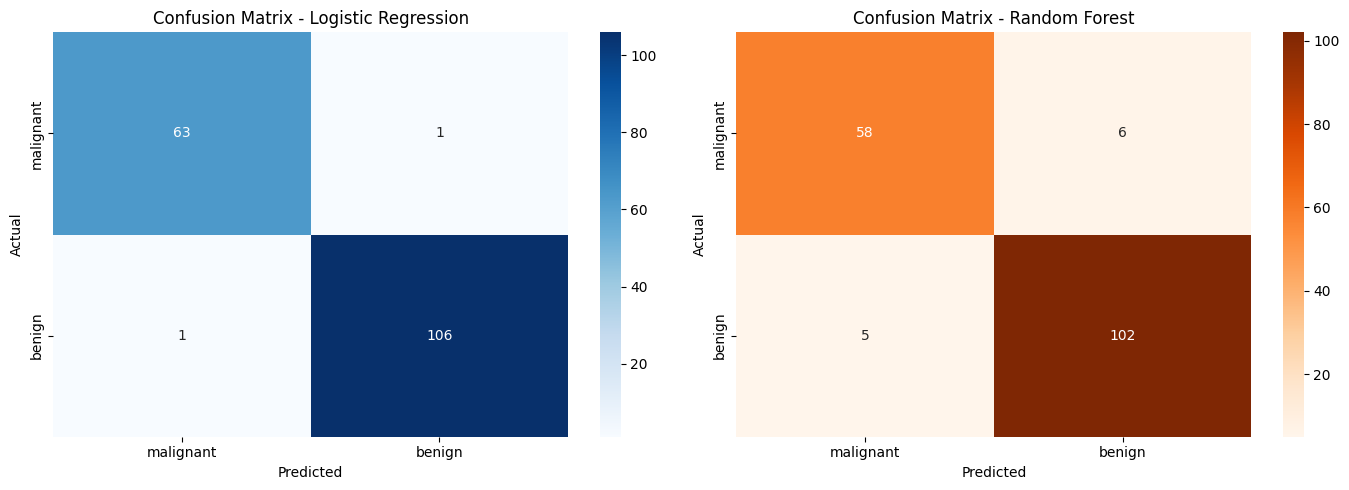

In [6]:
# 5. PERBANDINGAN AKURASI DAN CONFUSION MATRIX
acc_lr = accuracy_score(y_test, y_pred_lr)
acc_rf = accuracy_score(y_test, y_pred_rf)

print(f"Akurasi Logistic Regression: {acc_lr * 100:.2f}%")
print(f"Akurasi Random Forest: {acc_rf * 100:.2f}%")

# Plot Confusion Matrix secara Berdampingan
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_rf = confusion_matrix(y_test, y_pred_rf)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues", xticklabels=data.target_names, yticklabels=data.target_names, ax=axes[0])
axes[0].set_title("Confusion Matrix - Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Oranges", xticklabels=data.target_names, yticklabels=data.target_names, ax=axes[1])
axes[1].set_title("Confusion Matrix - Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()